### Exploración y limpieza de datos

#### 1. Importación de librerías

In [31]:
import pandas as pd  # leer el csv
import numpy as np # operaciones matemáticas
import matplotlib.pyplot as plt # generar gráficas
import seaborn as sns # visualizaciones estadísticas

#### 2. Cargar el dataset

In [32]:
df = pd.read_csv( # leer el archivo csv
    "../data/raw/diabetes_012_health_indicators_BRFSS2015.csv"
)

df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


#### 3. Data Understanding

Se realiza una exploración inicial del conjunto de datos para conocer la cantidad de observaciones, variables disponibles y los tipos de datos.

In [33]:
# DIMENSIONES DEL DATASET

print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Número de filas: 253680
Número de columnas: 22


In [34]:
# INFORMACIÓN GENERAL
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

#### 3.1 Interpretación de resultados

El conjunto de datos cuenta con 253680 observaciones y 22 variables, de las cuales 21 las podemos considerar como variables predictoras y la restante a variable objetivo (Diabetes_012).

No se presentaron valores nulos y todas las variables se almacenan como float64.

#### 4. Clasificación de variables

Debido al tipo de dato con el que se almacenan las variables, hay que verificar la naturaleza estadística de los datos para elegir las mejores técincas de análisis, visualización y limpieza de cada uno.

In [35]:
# Identificar la cantidad de valores distintos por variable
df.nunique()

Diabetes_012             3
HighBP                   2
HighChol                 2
CholCheck                2
BMI                     84
Smoker                   2
Stroke                   2
HeartDiseaseorAttack     2
PhysActivity             2
Fruits                   2
Veggies                  2
HvyAlcoholConsump        2
AnyHealthcare            2
NoDocbcCost              2
GenHlth                  5
MentHlth                31
PhysHlth                31
DiffWalk                 2
Sex                      2
Age                     13
Education                6
Income                   8
dtype: int64

In [36]:
# Mostrar los valores distintos de cada variable
for columna in df.columns:
    print(columna, ":", sorted(df[columna].unique()))

Diabetes_012 : [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
HighBP : [np.float64(0.0), np.float64(1.0)]
HighChol : [np.float64(0.0), np.float64(1.0)]
CholCheck : [np.float64(0.0), np.float64(1.0)]
BMI : [np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0

#### 4.1 Interpretación de resultados

A partir de los valores únicos, podemos clasificar las variables del dataset en cuatro grupos:

**Variables cualitativas nominales binarias (14):**
- HighBP, HighChol, CholCheck, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, Fruits, Veggies, HvyAlcoholConsump, AnyHealthcare, NoDocbcCost, DiffWalk y Sex.
- Únicamente contienen los valores 0 y 1.

**Variables cualitativas ordinales (5):**
- Diabetes_012: de 0 a 2.
- GenHlth: de 1 a 5.
- Age: de 1 a 13.
- Education: de 1 a 6.
- Income: de 1 a 8.

Sus valores representan categorías que tienen un orden.

**Variables cuantitativas discretas (2):**
- MentHlth y PhysHlth.
- Ambas contienen valores enteros de 0 a 30.

**Variables cuantitativas continuas (1):**
- BMI: presenta 84 valores distintos, con un mínimo de 12 y un máximo de 98. Aunque es una variable continua, sus valores están registrados como enteros.

#### 5. Detección de valores faltantes

Se analiza la existencia de valores faltantes en cada variable del dataset, para verificar si es necesario utilizar alguna técnica de imputación o eliminación de registros.

Aunque durante la exploración inicial con df.info() ya se observó que no existen valores nulos, se realiza esta comprobación específica para confirmar y documentar su ausencia como parte del proceso de limpieza de datos.

In [37]:
# Cantidad total de valores faltantes en el dataset
print("Total de valores faltantes:", df.isnull().sum().sum())

Total de valores faltantes: 0


#### 6. Detección de registros duplicados

Se analiza si existen observaciones que contienen los mismos valores en todos sus variables. En caso de encontrar duplicados, se evaluará la opción de eliminarlos o si es conveniente conservarlos, considerando que varias personas pudieron haber respondido lo mismo. 

In [38]:
# Identificar la cantidad de registros duplicados
duplicados = df.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 23899


In [39]:
# Calcular el porcentaje de registros duplicados
porcentaje = (duplicados / len(df)) * 100

print(f"Porcentaje de duplicados: {porcentaje:.2f}%")

Porcentaje de duplicados: 9.42%


In [40]:
# Mostrar ejemplos de registros duplicados
df[df.duplicated(keep=False)].head(10)

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,2.0,0.0,1.0,10.0,6.0,8.0
25,0.0,0.0,0.0,1.0,32.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,5.0,6.0,8.0
29,0.0,0.0,1.0,1.0,31.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
44,0.0,0.0,1.0,1.0,31.0,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
52,2.0,1.0,1.0,1.0,27.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,0.0,30.0,1.0,0.0,10.0,4.0,5.0
53,0.0,0.0,0.0,1.0,31.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,10.0,5.0,6.0
57,0.0,0.0,1.0,1.0,24.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,10.0,6.0,8.0
70,0.0,1.0,1.0,1.0,27.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,12.0,5.0,5.0
80,0.0,1.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,7.0,6.0,8.0
113,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,8.0,6.0,8.0


#### 6.1 Análisis de duplicados por clase

Se analiza la distribución de los registros duplicados según la variable objetivo, para determinar si eliminarlos podría afectar a la proporción de clases.

In [41]:
# Distribución original de las clases
df["Diabetes_012"].value_counts().sort_index()

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

In [42]:
# Distribución de los registros duplicados por clase
df[df.duplicated()]["Diabetes_012"].value_counts().sort_index()

Diabetes_012
0.0    23648
1.0        2
2.0      249
Name: count, dtype: int64

In [43]:
# Distribución de las clases sin duplicados
df.drop_duplicates()["Diabetes_012"].value_counts().sort_index()

Diabetes_012
0.0    190055
1.0      4629
2.0     35097
Name: count, dtype: int64

#### 6.1.1 Interpretación de resultados

Se encontraron 23,899 registros duplicados, que corresponden al 9.42% del dataset.

Al analizar los duplicados por clase, se encontró lo siguiente:
- Clase 0: 23,648 duplicados.
- Clase 1: 2 duplicados.
- Clase 2: 249 duplicados.

La mayoría de los duplicados pertenece a la clase 0, por lo tanto, eliminarlos alteraría la distribución de las clases. 

Debido a que estos resultados provienen de que la mayoría de variables son binarias y en general, categóricas, es probable que más de una persona haya respondido lo mismo en la encuesta. Es por ello que eliminarlas estaría poco justificado, al no ser comprobable que sea un error y se decidió conservarlas.

#### 7. Validación de rangos y valores permitidos.

Se utilizan los valores identificados anteriormente para verificar que las variables respeten sus rangos permitidos y detectar posibles errores de captura o inconsistencias.

##### 7.1 Variables binarias

In [44]:
variables_binarias = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

In [45]:
# Detectar valores inválidos en variables binarias
for columna in variables_binarias:
    invalidos = (~df[columna].isin([0, 1])).sum()
    print(columna, ":", invalidos)

HighBP : 0
HighChol : 0
CholCheck : 0
Smoker : 0
Stroke : 0
HeartDiseaseorAttack : 0
PhysActivity : 0
Fruits : 0
Veggies : 0
HvyAlcoholConsump : 0
AnyHealthcare : 0
NoDocbcCost : 0
DiffWalk : 0
Sex : 0


##### 7.2 Variables ordinales y cuantitativas discretas

In [46]:
rangos = {
    "Diabetes_012": (0, 2),
    "GenHlth": (1, 5),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30)
}

In [47]:
# Detectar valores fuera de los rangos permitidos
for columna, (minimo, maximo) in rangos.items():
    invalidos = (~df[columna].between(minimo, maximo)).sum()
    print(columna, ":", invalidos)

Diabetes_012 : 0
GenHlth : 0
Age : 0
Education : 0
Income : 0
MentHlth : 0
PhysHlth : 0


#### 7.3 Interpretación de resultados

No se encontraron valores inválidos en las variables binarias, ordinales y cuantitativas discretas, ya que todas cumplen con los rangos establecidos para la comprobación. Por lo tanto, no es necesario eliminar ni corregir ningún registro.


#### 8. Diagnóstico estadístico descriptivo

Se analizan las medidas de tendencia central, dispersión y posición de las variables cuantitativas para conocer
el comportamiento de los datos e identificar posibles valores atípicos.

In [48]:
# ESTADÍSTICA DESCRIPTIVA
variables_cuantitativas = ["BMI", "MentHlth", "PhysHlth"]

# Obtener las principales medidas estadísticas
df[variables_cuantitativas].describe()

,BMI,MentHlth,PhysHlth
count,253680.000000,253680.000000,253680.000000
mean,28.382364,3.184772,4.242081
std,6.608694,7.412847,8.717951
min,12.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000
75%,31.000000,2.000000,3.000000
max,98.000000,30.000000,30.000000


##### 8.1. Interpretación de resultados

BMI presenta una mediana de 27 y el 50 % central de los valores se encuentra entre 24 y 31. MentHlth y PhysHlth tienen una mediana de 0 y valores entre 0 y 30. Se revisarán los posibles valores atípicos antes de decidir si es necesario modificarlos.

#### 9. Detección y tratamiento de outliers

Se utiliza el rango intercuartílico (IQR) para detectar posibles valores atípicos en las tres variables cuantitativas. Las variables categóricas ya fueron revisadas mediante la validación de códigos.

In [49]:
# Calcular límites y cantidad de outliers por variable
for columna in variables_cuantitativas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    inferior = Q1 - 1.5 * IQR
    superior = Q3 + 1.5 * IQR
    outliers = ((df[columna] < inferior) | (df[columna] > superior)).sum()
    print(columna, "| Límites:", inferior, superior)
    print(f"Outliers: {outliers} ({outliers / len(df) * 100:.2f}%)")

BMI | Límites: 13.5 41.5
Outliers: 9847 (3.88%)
MentHlth | Límites: -3.0 5.0
Outliers: 36208 (14.27%)
PhysHlth | Límites: -4.5 7.5
Outliers: 40949 (16.14%)


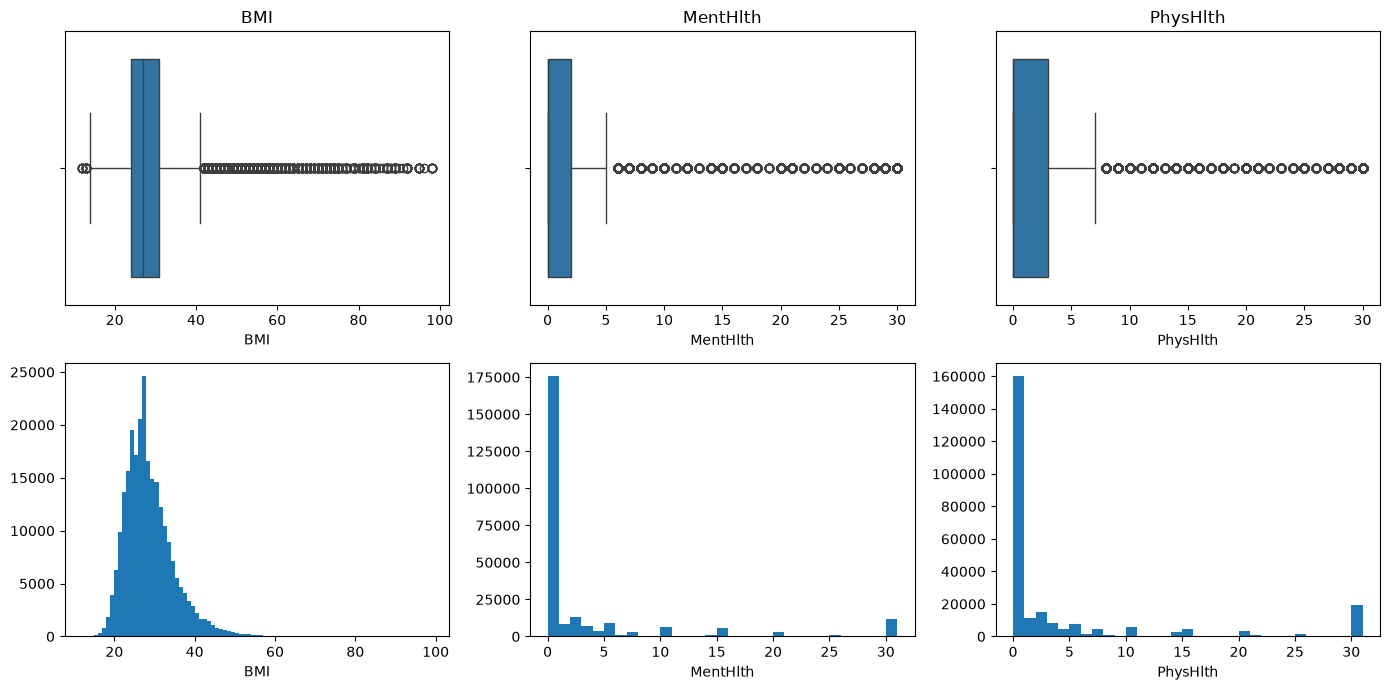

In [50]:
# Visualizar los valores atípicos y la distribución
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, columna in enumerate(variables_cuantitativas):
    sns.boxplot(x=df[columna], ax=axes[0, i])
    axes[1, i].hist(df[columna], bins=range(int(df[columna].min()), int(df[columna].max()) + 2))
    axes[0, i].set_title(columna)
    axes[1, i].set_xlabel(columna)
plt.tight_layout()
plt.show()

##### 9.1 Interpretación y tratamiento

- BMI: 9,847 valores atípicos (3.88 %). No se cuenta con evidencia de que sean errores de captura.
- MentHlth: 36,208 valores atípicos (14.27 %).
- PhysHlth: 40,949 valores atípicos (16.14 %).

En MentHlth y PhysHlth los valores señalados por IQR siguen dentro del intervalo de 0 a 30 días. Eliminar estos registros podría perder información relevante para el análisis.

Se decide conservar los valores originales. No se aplican recortes arbitrarios ni se considera que un outlier sea automáticamente un error.

In [51]:
# Conservar los registros y convertir los valores enteros a int
assert (df % 1 == 0).all().all(), "Existen valores no enteros"
df_clean = df.astype(int)

#### 10. Distribución de la variable objetivo

Se revisa la proporción de las tres clases para identificar si existe desbalance antes de entrenar los modelos.

              Registros  Porcentaje
Diabetes_012                       
0                213703       84.24
1                  4631        1.83
2                 35346       13.93


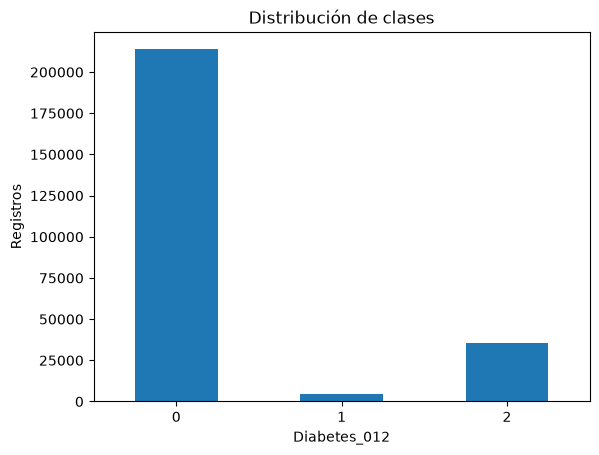

In [52]:
# Cantidad y porcentaje de registros por clase
conteo = df_clean["Diabetes_012"].value_counts().sort_index()
print(pd.DataFrame({"Registros": conteo, "Porcentaje": (conteo / len(df_clean) * 100).round(2)}))
conteo.plot(kind="bar", rot=0, title="Distribución de clases")
plt.xlabel("Diabetes_012")
plt.ylabel("Registros")
plt.show()

La clase 1 es la menos representada. Se conserva la clasificación original de tres clases y se considerará el desbalance durante el entrenamiento.

#### 11. Análisis de variables

Se utiliza Spearman para explorar relaciones entre las características y detectar posibles redundancias.

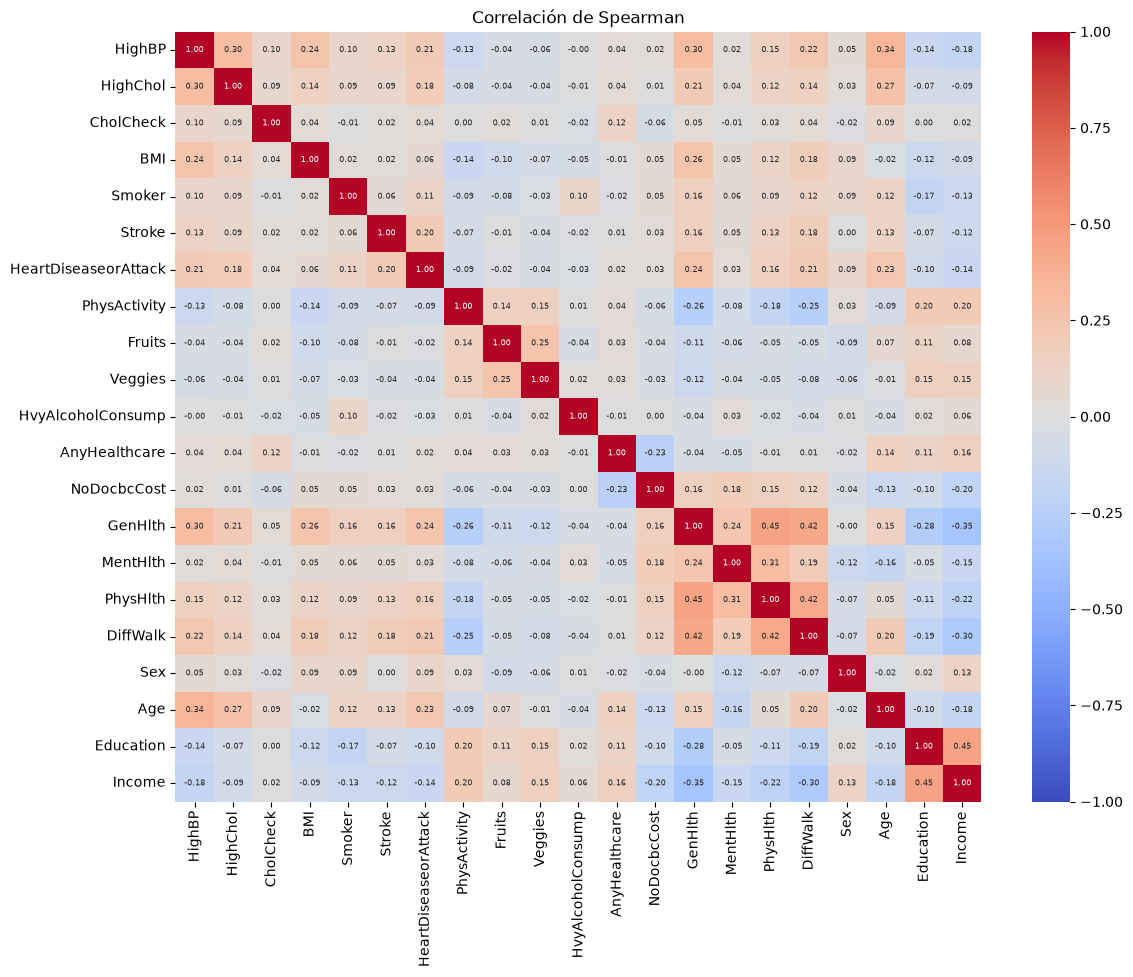

In [53]:
# Matriz de correlación de las características
X = df_clean.drop(columns=["Diabetes_012"])
y = df_clean["Diabetes_012"]

corr = X.corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6})
plt.title("Correlación de Spearman")
plt.show()

#### 12. División de entrenamiento y prueba

Se comparte una división aproximada de 80/20 para los modelos supervisados. Los perfiles idénticos se mantienen en el mismo conjunto para evitar fuga de información.

In [54]:
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
grupos = pd.util.hash_pandas_object(X, index=False)
division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(division.split(X, y, groups=grupos))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

assert not set(grupos.iloc[train_idx]) & set(grupos.iloc[test_idx])
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
pd.DataFrame({"Entrenamiento (%)": y_train.value_counts(normalize=True)*100,
              "Prueba (%)": y_test.value_counts(normalize=True)*100}).round(2)

Entrenamiento: (202940, 21)
Prueba: (50740, 21)


,Entrenamiento (%),Prueba (%)
Diabetes_012,,
0,84.24,84.24
2,13.94,13.92
1,1.82,1.84


##### 12.1 Relevancia de las variables

Se calcula la información mutua solo con entrenamiento. La tabla orienta la selección de características de cada algoritmo, no se eliminan variables automáticamente.

In [55]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train, y_train, discrete_features=True, random_state=SEED)
relevancia = pd.Series(mi, index=X_train.columns, name="Información mutua")
relevancia = relevancia.sort_values(ascending=False)
relevancia

GenHlth                 0.047410
HighBP                  0.037163
BMI                     0.029911
Age                     0.022217
HighChol                0.021688
DiffWalk                0.021358
PhysHlth                0.015078
Income                  0.015074
HeartDiseaseorAttack    0.013497
Education               0.008373
PhysActivity            0.007128
Stroke                  0.004811
CholCheck               0.003364
MentHlth                0.003114
Smoker                  0.002165
HvyAlcoholConsump       0.001979
Veggies                 0.001667
Fruits                  0.000906
NoDocbcCost             0.000710
Sex                     0.000521
AnyHealthcare           0.000162
Name: Información mutua, dtype: float64

#### 13. Normalización de datos

Se utiliza StandardScaler para las siete variables no binarias. Las binarias conservan sus códigos. El árbol de decisión utiliza datos sin escalar. Para regresión logística y KNN se ajusta el escalador solo con entrenamiento. Para K-Means exploratorio se prepara un conjunto independiente sin la variable objetivo. El escalamiento no elimina los outliers.

In [56]:
from sklearn.preprocessing import StandardScaler

cols_escalar = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
scaler = StandardScaler()
X_train_scaled = X_train.astype(float)
X_test_scaled = X_test.astype(float)

# Ajustar solo con entrenamiento
X_train_scaled[cols_escalar] = scaler.fit_transform(X_train[cols_escalar])
X_test_scaled[cols_escalar] = scaler.transform(X_test[cols_escalar])

pd.DataFrame({"Media antes": X_train[cols_escalar].mean(),
              "Desv. antes": X_train[cols_escalar].std(),
              "Media después": X_train_scaled[cols_escalar].mean(),
              "Desv. después": X_train_scaled[cols_escalar].std()}).round(3)

,Media antes,Desv. antes,Media después,Desv. después
BMI,28.390,6.623,0.0,1.0
MentHlth,3.200,7.433,-0.0,1.0
PhysHlth,4.251,8.722,0.0,1.0
GenHlth,2.512,1.068,-0.0,1.0
Age,8.033,3.054,-0.0,1.0
Education,5.050,0.986,-0.0,1.0
Income,6.053,2.070,0.0,1.0


In [57]:
# Datos para agrupamiento exploratorio sin variable objetivo
scaler_kmeans = StandardScaler()
X_kmeans = X.astype(float)
X_kmeans[cols_escalar] = scaler_kmeans.fit_transform(X[cols_escalar])

#### 14. Tratamiento del desbalance

Se genera una variante de entrenamiento mediante submuestreo aleatorio para KNN. Se conserva también el entrenamiento completo para comparar resultados. No se modifica el conjunto de prueba ni se balancea K-Means.

In [58]:
# Submuestreo sin librerías adicionales
entrenamiento = X_train_scaled.copy()
entrenamiento["Diabetes_012"] = y_train
n_min = y_train.value_counts().min()

balanceado = pd.concat([
    grupo.sample(n=n_min, random_state=SEED)
    for _, grupo in entrenamiento.groupby("Diabetes_012")
]).sample(frac=1, random_state=SEED)

X_train_bal = balanceado.drop(columns=["Diabetes_012"])
y_train_bal = balanceado["Diabetes_012"]
pd.DataFrame({"Antes": y_train.value_counts(),
              "Después": y_train_bal.value_counts()})

,Antes,Después
Diabetes_012,,
0,170959,3697
2,28284,3697
1,3697,3697


#### 15. Guardado de datos procesados

Se guardan los datos limpios, las variantes para los modelos y los escaladores para reutilizarlos en el dashboard.

In [59]:
from pathlib import Path
import joblib

ruta = Path("../data/processed")
ruta.mkdir(parents=True, exist_ok=True)

archivos = {
    "diabetes_clean": df_clean,
    "X_train": X_train, "X_test": X_test,
    "y_train": y_train, "y_test": y_test,
    "X_train_scaled": X_train_scaled, "X_test_scaled": X_test_scaled,
    "X_train_bal": X_train_bal, "y_train_bal": y_train_bal,
    "X_kmeans": X_kmeans
}

for nombre, datos in archivos.items():
    assert not datos.isnull().any().any()
    datos.to_csv(ruta / f"{nombre}.csv", index=False)
    print(nombre, datos.shape)

joblib.dump(scaler, ruta / "scaler.joblib")
joblib.dump(scaler_kmeans, ruta / "scaler_kmeans.joblib")

diabetes_clean (253680, 22)
X_train (202940, 21)
X_test (50740, 21)
y_train (202940,)
y_test (50740,)
X_train_scaled (202940, 21)
X_test_scaled (50740, 21)
X_train_bal (11091, 21)
y_train_bal (11091,)
X_kmeans (253680, 21)


['..\\data\\processed\\scaler_kmeans.joblib']